**SEANCE:** 1


**NOM:** Yoann TOSSA


**PORTEUR #:** P4


**ETAPES ASSIGNEES:** 1.7, 1.11, 1.12


# Carnet de démarrage — sujet 05 · Santander Satisfaction

**Objectif du sujet** : repérer le client qui va se plaindre.

Ce carnet est un **châssis**, pas une solution. Il fait quatre choses et s'arrête :

1. il **trouve** vos fichiers, quelle que soit la plateforme ;
2. il **charge** la table efficacement — cache Parquet construit une fois, projection de colonnes ;
3. il **profile** les données : dimensions, types, cible, manquants ;
4. il **écrit** une soumission au bon format, avec une valeur de référence volontairement nulle.

**Ce qu'il ne fait pas** : choisir votre métrique, votre découpage de validation, votre modèle, ni vos
variables. Ces décisions sont le sujet, et c'est ce que la grille note.

3,96 % de mécontents. 97 colonnes sont constantes sur un échantillon.

---

## Où mettre ce carnet

| Plateforme | Ce qu'il faut faire |
|---|---|
| **Le dossier du sujet** | **(lien du Drive communiqué par l’enseignant)** — téléchargez-le avant tout (le lien figure aussi dans l'énoncé) |
| **En local (VS Code, Jupyter)** | placez le carnet **dans le dossier téléchargé**, ou définissez `DONNEES_PROJET` vers ce dossier |
| **Google Colab** | déposez les fichiers dans `MyDrive/Sujet_05_Santander_Satisfaction/` — le carnet les trouvera ; ou téléversez-les dans `/content/` |
| **Kaggle** | créez un jeu de données avec vos fichiers, **Add Input** — `/kaggle/input` est exploré automatiquement |

**Rien n'est codé en dur** : le carnet cherche, et s'il ne trouve pas, il **dit précisément** ce qu'il a
cherché et où.


## Les fichiers de ce sujet

| Fichier | Rôle |
|---|---|
| `train.csv` | entraînement ou annexe |
| `a_decider.csv` | à prédire — la cible est absente |

**Format de sortie attendu** : `ID,TARGET`.
**Colonne d'identifiant** : `ID`.
**Fichier à produire** : `soumission.csv`, à la racine de votre dépôt.


In [15]:
# --- 1. Réglages --------------------------------------------------------------
from pathlib import Path
import os
import pandas as pd

# Où télécharger vos données — le dossier de votre sujet sur le Drive du cours.
LIEN_DRIVE = "__LIEN__"

# ECHANTILLON : nombre de lignes lues pour démarrer. None = tout lire.
ECHANTILLON = 200_000
DOSSIER_CACHE = Path.cwd() / "_cache_parquet"


In [16]:
import os
for racine, dossiers, fichiers in os.walk('/kaggle/input'):
    if fichiers:
        print(racine, fichiers)

/kaggle/input/competitions/rappels-et-sur-réservation-des-créneaux ['sample_submission.csv', 'table_activite.csv', 'machine_failure.csv', 'train.csv', 'test.csv']
/kaggle/input/datasets/yoannjustbe/santander-satisfaction ['a_decider.csv', 'train.csv']


In [17]:
import os
os.environ['DONNEES_PROJET'] = '/kaggle/input/datasets/yoannjustbe/santander-satisfaction'

In [18]:
# --- 2. Trouver les données, sans rien coder en dur --------------------------
FICHIERS_ATTENDUS = ['train.csv', 'a_decider.csv']
SUJET = "Sujet_05_Santander_Satisfaction"


def trouver_donnees(fichiers=FICHIERS_ATTENDUS, sujet=SUJET):
    """Cherche le dossier qui contient TOUS les fichiers attendus."""
    essais = []
    pistes = []
    if os.environ.get("DONNEES_PROJET"):
        pistes.append(Path(os.environ["DONNEES_PROJET"]))
    ici = Path.cwd().resolve()
    pistes += [ici, ici / "donnees", ici / sujet]
    pistes += list(ici.parents)[:4]
    pistes += [Path("/kaggle/input"), Path("/content"), Path("/content/drive/MyDrive")]

    for racine in pistes:
        if not racine.exists():
            continue
        candidates = [racine, racine / sujet]
        if racine.name in ("input", "MyDrive"):
            candidates += [d for d in racine.iterdir() if d.is_dir()]
        for c in candidates:
            essais.append(str(c))
            if all((c / f).is_file() for f in fichiers):
                return c
    raise FileNotFoundError(
        "Dossier de données introuvable.\n"
        "Il faut un dossier contenant : " + ", ".join(fichiers) + "\n"
        "Solutions : placez le carnet à côté de ce dossier, "
        "ou définissez DONNEES_PROJET=/chemin/vers/le/dossier.\n"
        "Chemins essayés : " + str(essais[:12])
    )


DOSSIER = trouver_donnees()
print("dossier de données :", DOSSIER)
print("fichiers vus :", sorted(p.name for p in DOSSIER.iterdir() if p.is_file())[:12])


dossier de données : /kaggle/input/datasets/yoannjustbe/santander-satisfaction
fichiers vus : ['a_decider.csv', 'train.csv']


In [19]:
# --- 3. Chargement (table légère) ---------------------------------------------
def table(nom, colonnes=None, morceaux=None, complet=False):
    """Ouvre un CSV directement avec pandas — la table tient en mémoire."""
    source = DOSSIER / nom
    if not source.is_file():
        raise FileNotFoundError(f"{nom} introuvable dans {DOSSIER}")
    if morceaux:
        return pd.read_csv(source, usecols=colonnes, chunksize=morceaux)
    return pd.read_csv(source, usecols=colonnes, nrows=None if complet else ECHANTILLON)


In [20]:
# --- 4. Charger et regarder ---------------------------------------------------
entrainement = table("train.csv")
print("dimensions :", entrainement.shape)
print("colonnes :", len(entrainement.columns))
entrainement.head()


dimensions : (60816, 371)
colonnes : 371


,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
0,130807,2,26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117310.979016,0
1,78981,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,85472.340000,0
2,50325,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,317769.240000,0
3,146646,2,30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,76209.960000,0
4,136536,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,302754.000000,0


In [21]:
# --- 5. Profil de la cible ----------------------------------------------------
CIBLE = "TARGET"
if CIBLE in entrainement.columns:
    serie = entrainement[CIBLE]
    print("type :", serie.dtype)
    print("manquants :", int(serie.isna().sum()))
    print(serie.describe())
    if serie.nunique() <= 20:
        print(serie.value_counts(normalize=True).sort_index())
else:
    print(f"la cible {CIBLE} est absente de cette table — normal pour la table à prédire")


type : int64
manquants : 0
count    60816.000000
mean         0.039562
std          0.194929
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: TARGET, dtype: float64
TARGET
0    0.960438
1    0.039562
Name: proportion, dtype: float64


In [22]:
# --- 6. Soumission de RÉFÉRENCE (format seulement) ----------------------------
# Cette valeur n'a AUCUNE prétention prédictive : elle vérifie le format.
COLONNES_SORTIE = ['ID', 'TARGET']


def ecrire_soumission(identifiants, valeurs=None, chemin="soumission.csv"):
    """Écrit le fichier attendu. `valeurs` peut être une colonne, ou une matrice de probabilités."""
    sortie = pd.DataFrame({"ID": identifiants})
    if len(COLONNES_SORTIE) == 2:
        sortie["TARGET"] = valeurs
    else:
        n = len(COLONNES_SORTIE) - 1
        matrice = valeurs if valeurs is not None else [[1.0 / n] * n for _ in identifiants]
        for j, colonne in enumerate(COLONNES_SORTIE[1:]):
            sortie[colonne] = [ligne[j] for ligne in matrice]
    sortie.to_csv(chemin, index=False)
    print(f"écrit : {chemin} · {len(sortie):,} lignes · colonnes {list(sortie.columns)}")
    if len(COLONNES_SORTIE) > 2:
        print("somme par ligne (doit valoir 1) :", sortie.iloc[:, 1:].sum(axis=1).round(6).unique()[:3])
    return sortie


a_predire = table("a_decider.csv", colonnes=["ID"], complet=True)
identifiants = a_predire["ID"].drop_duplicates().to_numpy()
print("identifiants à prédire :", len(identifiants))
ecrire_soumission(identifiants)


identifiants à prédire : 15204
écrit : soumission.csv · 15,204 lignes · colonnes ['ID', 'TARGET']


,ID,TARGET
0,38893,None
1,133597,None
2,24908,None
3,19551,None
4,36051,None
...,...,...
15199,28686,None
15200,66259,None
15201,44895,None
15202,33938,None


In [35]:
# --- 7. Le travail commence ICI ---------------------------------------
# À vous de décider, et de justifier :
#   - la métrique, et ce qu'elle coûte ;
#   - le découpage de validation ;
#   - les variables, leur encodage, leur imputation ;
#   - le modèle, son réglage, son seuil.

In [24]:
import pandas as pd

train = pd.read_csv(DOSSIER / "train.csv")
a_decider = pd.read_csv(DOSSIER / "a_decider.csv")

print("train :", train.shape)
print("a_decider :", a_decider.shape)

train : (60816, 371)
a_decider : (15204, 370)


**#--- 1.7a : Doublons de lignes ---**

In [25]:
n_doublons_lignes = train.duplicated().sum()
print(f"Lignes dupliquées : {n_doublons_lignes}")

if n_doublons_lignes > 0:
    print("\nExemple de doublons :")
    masque = train.duplicated(keep=False)
    display(train[masque].head(6))
else:
    print("Aucune ligne dupliquée — le jeu est propre sur ce point.")

Lignes dupliquées : 0
Aucune ligne dupliquée — le jeu est propre sur ce point.


**# === 1.7b : Doublons de colonnes ===**

In [26]:
colonnes = [c for c in train.columns if c != "TARGET"]
groupes_doublons = {}
deja_vu = {}

for col in colonnes:
    h = hash(train[col].values.tobytes())
    if h in deja_vu:
        ref = deja_vu[h]
        if ref not in groupes_doublons:
            groupes_doublons[ref] = []
        groupes_doublons[ref].append(col)
    else:
        deja_vu[h] = col

if groupes_doublons:
    print(f"{sum(len(v) for v in groupes_doublons.values())} colonne(s) dupliquée(s) :")
    for ref, copies in groupes_doublons.items():
        print(f"  '{ref}' == {copies}")
else:
    print("Aucune colonne dupliquée.")

64 colonne(s) dupliquée(s) :
  'ind_var2_0' == ['ind_var2', 'ind_var27_0', 'ind_var28_0', 'ind_var28', 'ind_var27', 'ind_var41', 'ind_var46_0', 'ind_var46', 'num_var27_0', 'num_var28_0', 'num_var28', 'num_var27', 'num_var41', 'num_var46_0', 'num_var46', 'saldo_var28', 'saldo_var27', 'saldo_var41', 'saldo_var46', 'imp_amort_var18_hace3', 'imp_amort_var34_hace3', 'imp_reemb_var13_hace3', 'imp_reemb_var17_hace3', 'imp_reemb_var33_hace3', 'imp_trasp_var17_out_hace3', 'imp_trasp_var33_out_hace3', 'num_var2_0_ult1', 'num_var2_ult1', 'num_reemb_var13_hace3', 'num_reemb_var17_hace3', 'num_reemb_var33_hace3', 'num_trasp_var17_out_hace3', 'num_trasp_var33_out_hace3', 'saldo_var2_ult1', 'saldo_medio_var13_medio_hace3']
  'ind_var13_medio_0' == ['ind_var13_medio']
  'ind_var18_0' == ['ind_var18']
  'ind_var26_0' == ['ind_var26']
  'ind_var25_0' == ['ind_var25']
  'ind_var6_0' == ['ind_var29_0']
  'ind_var6' == ['ind_var29']
  'ind_var32_0' == ['ind_var32']
  'ind_var34_0' == ['ind_var34']
  'ind_v

**# === 1.7c : Bilan ===**

In [27]:
colonnes_a_supprimer = [col for copies in groupes_doublons.values() for col in copies]

print("=== BILAN 1.7 — Doublons ===")
print(f"  Lignes dupliquées     : {n_doublons_lignes}")
print(f"  Colonnes dupliquées   : {len(colonnes_a_supprimer)}")
if colonnes_a_supprimer:
    print(f"  → Colonnes supprimables sans perte d'info : {colonnes_a_supprimer}")
else:
    print("  → Aucune suppression nécessaire.")

=== BILAN 1.7 — Doublons ===
  Lignes dupliquées     : 0
  Colonnes dupliquées   : 64
  → Colonnes supprimables sans perte d'info : ['ind_var2', 'ind_var27_0', 'ind_var28_0', 'ind_var28', 'ind_var27', 'ind_var41', 'ind_var46_0', 'ind_var46', 'num_var27_0', 'num_var28_0', 'num_var28', 'num_var27', 'num_var41', 'num_var46_0', 'num_var46', 'saldo_var28', 'saldo_var27', 'saldo_var41', 'saldo_var46', 'imp_amort_var18_hace3', 'imp_amort_var34_hace3', 'imp_reemb_var13_hace3', 'imp_reemb_var17_hace3', 'imp_reemb_var33_hace3', 'imp_trasp_var17_out_hace3', 'imp_trasp_var33_out_hace3', 'num_var2_0_ult1', 'num_var2_ult1', 'num_reemb_var13_hace3', 'num_reemb_var17_hace3', 'num_reemb_var33_hace3', 'num_trasp_var17_out_hace3', 'num_trasp_var33_out_hace3', 'saldo_var2_ult1', 'saldo_medio_var13_medio_hace3', 'ind_var13_medio', 'ind_var18', 'ind_var26', 'ind_var25', 'ind_var29_0', 'ind_var29', 'ind_var32', 'ind_var34', 'ind_var37', 'ind_var39', 'num_var13_medio', 'num_var18', 'num_var26', 'num_var25', '

In [30]:
from sklearn.metrics import roc_auc_score, roc_curve
import numpy as np
import matplotlib.pyplot as plt

CIBLE = "TARGET"
y = train[CIBLE]



**# === 1.11a : Distribution de la cible ===**


In [32]:
print("Distribution de TARGET :")
print(y.value_counts())
print(f"\nTaux de mécontents : {y.mean()*100:.2f} %")

Distribution de TARGET :
TARGET
0    58410
1     2406
Name: count, dtype: int64

Taux de mécontents : 3.96 %


**# === 1.11b : Modèle naïf vs aléatoire ===**

In [33]:
y_pred_naif = np.zeros(len(y))
exactitude_naif = (y == 0).mean()

np.random.seed(42)
y_pred_aleatoire = np.random.rand(len(y))
auc_aleatoire = roc_auc_score(y, y_pred_aleatoire)

print(f"Modèle naïf (prédit toujours 0) :")
print(f"  Exactitude : {exactitude_naif*100:.2f} %  ← chiffre trompeur")
print(f"  AUC        : 0.5000              ← pas mieux que le hasard")
print(f"\nModèle aléatoire :")
print(f"  AUC        : {auc_aleatoire:.4f}  ← converge vers 0.5")
print(f"\nPlancher métier (règle de la banque sans modèle) : AUC = 0.6890")

Modèle naïf (prédit toujours 0) :
  Exactitude : 96.04 %  ← chiffre trompeur
  AUC        : 0.5000              ← pas mieux que le hasard

Modèle aléatoire :
  AUC        : 0.4961  ← converge vers 0.5

Plancher métier (règle de la banque sans modèle) : AUC = 0.6890


**# === 1.11c : Courbe ROC de référence ===**

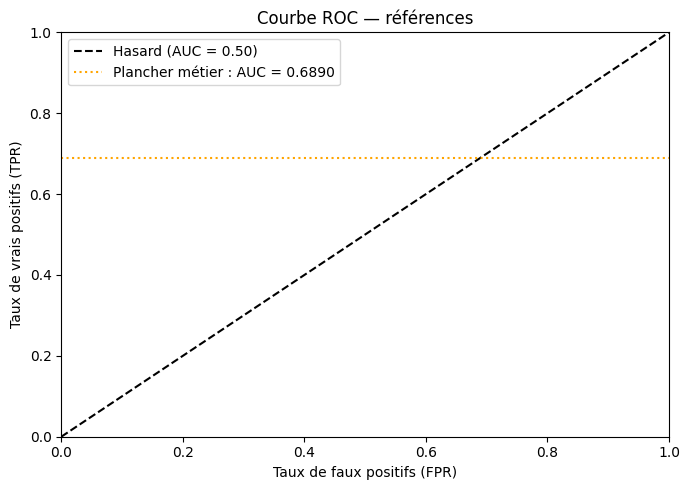

In [34]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot([0, 1], [0, 1], 'k--', label='Hasard (AUC = 0.50)')
ax.axhline(y=0.6890, color='orange', linestyle=':', label='Plancher métier : AUC = 0.6890')

ax.set_xlabel("Taux de faux positifs (FPR)")
ax.set_ylabel("Taux de vrais positifs (TPR)")
ax.set_title("Courbe ROC — références")
ax.legend()
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
plt.tight_layout()
plt.show()